<a href="https://colab.research.google.com/github/caiohenry-jpg/CalculoNumerico/blob/main/Atividade_interpola%C3%A7%C3%A3o_Turma_noite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Caio Henry | RA: 180374
Erros em métodos de interpolação

Modelo: T(x) = 18 + 2,4(x/6) + 2,5 sen(πx/6).
T(0) = 18 °C e T(6) = 20,4 °C.
T''(x) = −(2,5π²/36) sen(πx/6).
Com q(x) = (2,5kπ²/36) sen(πx/6), temos kT'' + q = 0.

ETAPA 1 - SETE SENSORES EXATOS
               Método    Emax (°C)     MAE (°C)    RMSE (°C)
      Lagrange global 8.468221e-05 1.917900e-05 3.270695e-05
Spline cúbica natural 5.060068e-04 1.841431e-04 2.391482e-04
    Spline quadrática 2.392716e-02 1.495017e-02 1.646552e-02
        Spline linear 8.229382e-02 3.650998e-02 4.396661e-02


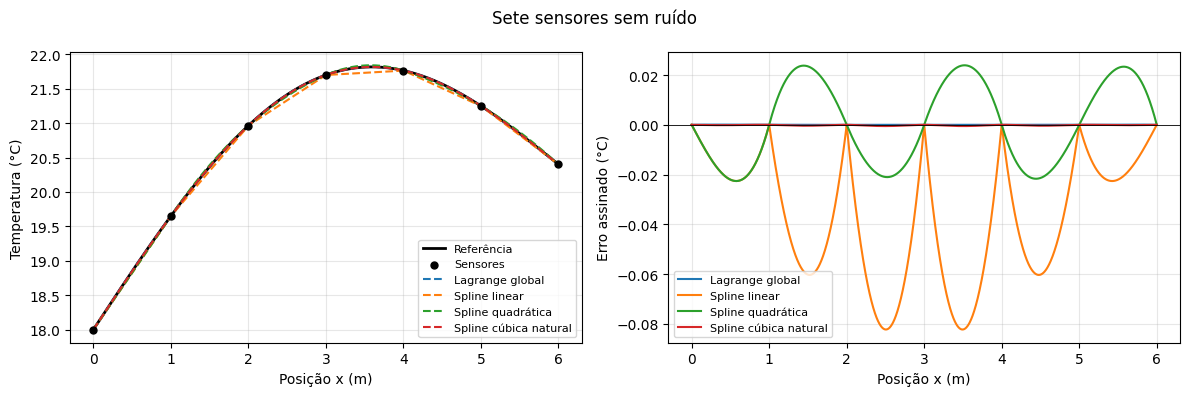


ETAPA 2 - QUANTIDADE E POSIÇÃO DOS SENSORES
 N               Nós    Emax (°C)     MAE (°C)    RMSE (°C)
 5     Equiespaçados 4.530257e-03 1.502231e-03 2.159567e-03
 5 Chebyshev-Lobatto 2.326599e-03 1.319894e-03 1.532697e-03
 9     Equiespaçados 1.043537e-06 1.719783e-07 3.438146e-07
 9 Chebyshev-Lobatto 2.167582e-07 9.973265e-08 1.202332e-07
13     Equiespaçados 5.913847e-11 6.006527e-12 1.545896e-11
13 Chebyshev-Lobatto 3.623768e-12 1.593982e-12 1.931936e-12
17     Equiespaçados 2.412293e-12 7.792179e-14 2.789196e-13
17 Chebyshev-Lobatto 1.421085e-14 2.915320e-15 3.903778e-15

O perfil é suave e a aproximação polinomial converge rapidamente.
Perto da precisão de máquina, diferenças muito pequenas refletem
também o arredondamento. Esse resultado não garante o mesmo
comportamento para outras funções.

ETAPA 3 - ERRO E TEMPO PARA N DE 4 A 40
 N                Método    Emax (°C)     MAE (°C)    RMSE (°C)  Construção (ms)  Avaliação (ms)
 4 Lagrange equiespaçado 1.090393e-01 6.011054e-02

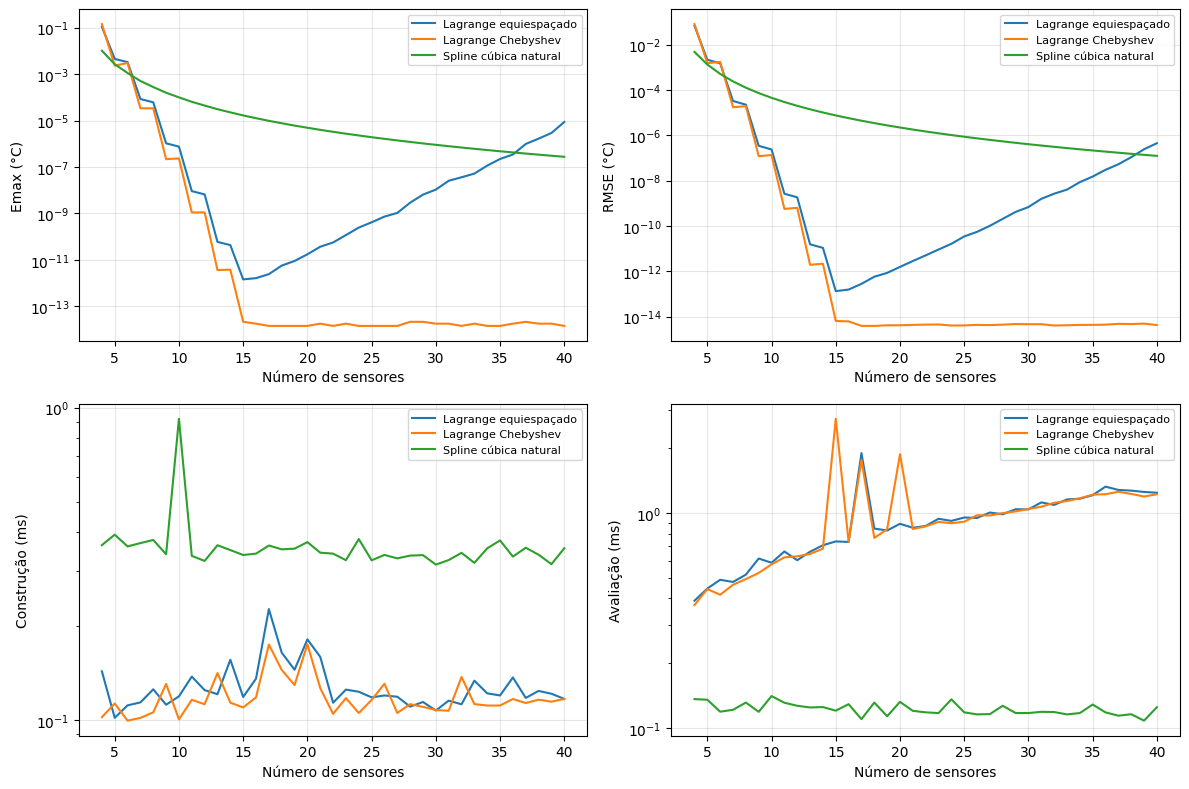


Os tempos são medianas de cinco repetições, após uma execução
inicial de aquecimento, e dependem do computador. A avaliação
usa sempre 2001 pontos. Os gráficos não entram na medição.

A forma baricêntrica evita expandir o polinômio, mas não elimina
a sensibilidade dos nós equiespaçados. Nesta implementação,
a construção dos pesos custa O(N²), e a avaliação custa O(MN),
sendo M a quantidade de pontos avaliados.

A spline cúbica usa um sistema de banda, com construção O(N),
e avaliação por trechos.

Não há garantia de um método superior em precisão, estabilidade
e custo para todo N. Para este perfil suave, Lagrange pode atingir
erros muito pequenos, mas o aumento do grau com nós equiespaçados
também pode ampliar os efeitos do arredondamento.

ETAPA 4 - SENSORES COM RUÍDO
Hipótese: ruído normal com média zero e desvio padrão de 0,1 °C.
As temperaturas prescritas nas extremidades permanecem exatas.
São usadas 50 realizações para cada quantidade de sensores.



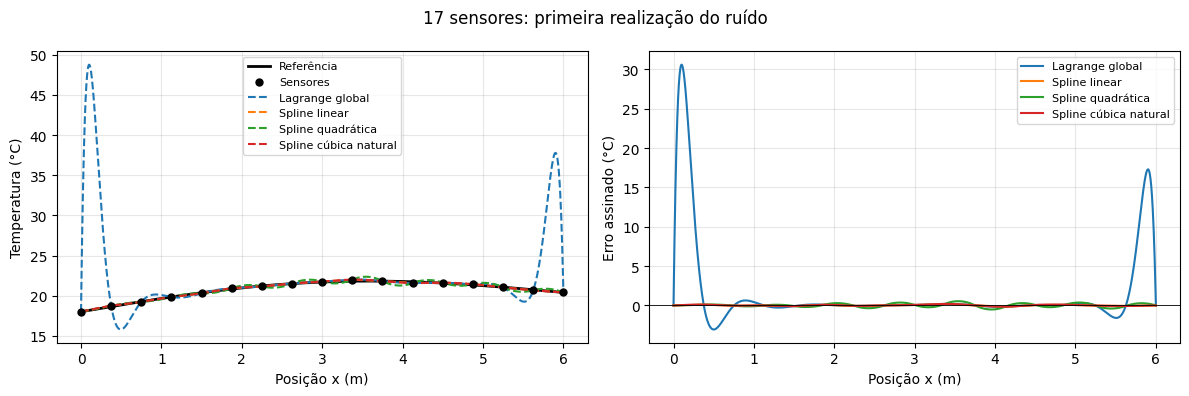

Médias das métricas nas 50 realizações:
 N                Método    Emax (°C)     MAE (°C)    RMSE (°C)
 7       Lagrange global 2.501613e-01 9.562235e-02 1.171983e-01
 7         Spline linear 1.745179e-01 6.494994e-02 8.071562e-02
 7     Spline quadrática 2.586662e-01 1.011281e-01 1.249800e-01
 7 Spline cúbica natural 1.673485e-01 7.068894e-02 8.590456e-02
17       Lagrange global 2.454199e+01 1.613063e+00 4.778167e+00
17         Spline linear 2.092012e-01 6.356700e-02 7.980179e-02
17     Spline quadrática 4.101887e-01 1.310306e-01 1.653122e-01
17 Spline cúbica natural 2.162298e-01 7.264322e-02 9.053814e-02

RECOMENDAÇÃO TÉCNICA
Com sete sensores exatos, escolheria Lagrange global para este perfil: Emax = 8.468e-05 °C e RMSE = 3.271e-05 °C.
A spline cúbica apresentou Emax = 5.060e-04 °C e RMSE = 2.391e-04 °C.

Com mais sensores, evitaria aumentar indefinidamente o grau
com nós equiespaçados. Se pudesse escolher as posições e os
dados fossem exatos, consideraria Chebyshev-Lobatto.
Para

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from time import perf_counter

print("Caio Henry | RA: 180374")
print("Erros em métodos de interpolação\n")

pd.set_option("display.float_format", lambda v: f"{v:.6e}")
L = 6.0

def temperatura_real(x):
    x = np.asarray(x, dtype=float)
    return 18 + 2.4*x/L + 2.5*np.sin(np.pi*x/L)

def lagrange(x, y):
    z = (np.asarray(x) - 3)/3
    d = z[:, None] - z[None, :]
    np.fill_diagonal(d, 1)
    w = 1/np.prod(d, axis=1)
    return BarycentricInterpolator(x, y, wi=w/np.max(np.abs(w)))

def spline_quadratica(x, y):
    x, y = np.asarray(x), np.asarray(y)
    h = np.diff(x)
    a = y[:-1].copy()
    b = np.zeros(len(h))
    c = np.zeros(len(h))
    b[0] = (y[1]-y[0])/h[0]

    for i in range(len(h)):
        c[i] = (y[i+1]-y[i]-b[i]*h[i])/h[i]**2
        if i < len(h)-1:
            b[i+1] = b[i] + 2*c[i]*h[i]

    def avaliar(z):
        z = np.asarray(z)
        j = np.clip(
            np.searchsorted(x, z, side="right")-1,
            0, len(h)-1
        )
        t = z-x[j]
        return a[j] + b[j]*t + c[j]*t**2

    return avaliar

def criar_metodos(x, y):
    return {
        "Lagrange global": lagrange(x, y),
        "Spline linear": interp1d(x, y, bounds_error=True),
        "Spline quadrática": spline_quadratica(x, y),
        "Spline cúbica natural": CubicSpline(x, y, bc_type="natural")
    }

def metricas(estimativa, referencia):
    erro = np.asarray(estimativa)-referencia
    return {
        "Emax (°C)": np.max(np.abs(erro)),
        "MAE (°C)": np.mean(np.abs(erro)),
        "RMSE (°C)": np.sqrt(np.mean(erro**2))
    }

def nos_chebyshev(N):
    return np.sort(
        L/2 + L/2*np.cos(np.arange(N)*np.pi/(N-1))
    )

def grafico(metodos, x, y, titulo):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(x_fino, T_fino, "k", lw=2, label="Referência")
    ax[0].scatter(
        x, y, color="black", s=25, zorder=5, label="Sensores"
    )

    for nome, metodo in metodos.items():
        valores = metodo(x_fino)
        ax[0].plot(x_fino, valores, "--", label=nome)
        ax[1].plot(x_fino, valores-T_fino, label=nome)

    ax[0].set_ylabel("Temperatura (°C)")
    ax[1].set_ylabel("Erro assinado (°C)")
    ax[1].axhline(0, color="black", lw=.6)

    for eixo in ax:
        eixo.set_xlabel("Posição x (m)")
        eixo.grid(alpha=.3)
        eixo.legend(fontsize=8)

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

x_fino = np.linspace(0, L, 2001)
T_fino = temperatura_real(x_fino)

print("Modelo: T(x) = 18 + 2,4(x/6) + 2,5 sen(πx/6).")
print("T(0) = 18 °C e T(6) = 20,4 °C.")
print("T''(x) = −(2,5π²/36) sen(πx/6).")
print("Com q(x) = (2,5kπ²/36) sen(πx/6), temos kT'' + q = 0.\n")


print("ETAPA 1 - SETE SENSORES EXATOS")

x7 = np.linspace(0, L, 7)
y7 = temperatura_real(x7)
m7 = criar_metodos(x7, y7)

tabela7 = pd.DataFrame([
    {"Método": nome, **metricas(m(x_fino), T_fino)}
    for nome, m in m7.items()
]).sort_values("RMSE (°C)")

print(tabela7.to_string(index=False))
grafico(m7, x7, y7, "Sete sensores sem ruído")


print("\nETAPA 2 - QUANTIDADE E POSIÇÃO DOS SENSORES")

linhas = []

for N in [5, 9, 13, 17]:
    distribuicoes = [
        ("Equiespaçados", np.linspace(0, L, N)),
        ("Chebyshev-Lobatto", nos_chebyshev(N))
    ]

    for tipo, x in distribuicoes:
        m = lagrange(x, temperatura_real(x))
        linhas.append({
            "N": N,
            "Nós": tipo,
            **metricas(m(x_fino), T_fino)
        })

tabela_nos = pd.DataFrame(linhas)
print(tabela_nos.to_string(index=False))

print("""
O perfil é suave e a aproximação polinomial converge rapidamente.
Perto da precisão de máquina, diferenças muito pequenas refletem
também o arredondamento. Esse resultado não garante o mesmo
comportamento para outras funções.
""")


print("ETAPA 3 - ERRO E TEMPO PARA N DE 4 A 40")

linhas = []

for N in range(4, 41):
    xe = np.linspace(0, L, N)
    xc = nos_chebyshev(N)
    ye = temperatura_real(xe)
    yc = temperatura_real(xc)

    casos = {
        "Lagrange equiespaçado": lambda: lagrange(xe, ye),
        "Lagrange Chebyshev": lambda: lagrange(xc, yc),
        "Spline cúbica natural": lambda: CubicSpline(
            xe, ye, bc_type="natural"
        )
    }

    for nome, construir in casos.items():
        construir()(x_fino)
        tempos_c, tempos_a = [], []

        for _ in range(5):
            inicio = perf_counter()
            m = construir()
            tempos_c.append(perf_counter()-inicio)

            inicio = perf_counter()
            valores = m(x_fino)
            tempos_a.append(perf_counter()-inicio)

        linhas.append({
            "N": N,
            "Método": nome,
            **metricas(valores, T_fino),
            "Construção (ms)": 1000*np.median(tempos_c),
            "Avaliação (ms)": 1000*np.median(tempos_a)
        })

tabela_estudo = pd.DataFrame(linhas)
print(tabela_estudo.to_string(index=False))

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

colunas = [
    "Emax (°C)",
    "RMSE (°C)",
    "Construção (ms)",
    "Avaliação (ms)"
]

for nome, grupo in tabela_estudo.groupby("Método", sort=False):
    for eixo, coluna in zip(ax.flat, colunas):
        eixo.semilogy(
            grupo["N"],
            np.maximum(grupo[coluna], 1e-16),
            label=nome
        )

for eixo, coluna in zip(ax.flat, colunas):
    eixo.set_xlabel("Número de sensores")
    eixo.set_ylabel(coluna)
    eixo.grid(alpha=.3)
    eixo.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("""
Os tempos são medianas de cinco repetições, após uma execução
inicial de aquecimento, e dependem do computador. A avaliação
usa sempre 2001 pontos. Os gráficos não entram na medição.

A forma baricêntrica evita expandir o polinômio, mas não elimina
a sensibilidade dos nós equiespaçados. Nesta implementação,
a construção dos pesos custa O(N²), e a avaliação custa O(MN),
sendo M a quantidade de pontos avaliados.

A spline cúbica usa um sistema de banda, com construção O(N),
e avaliação por trechos.

Não há garantia de um método superior em precisão, estabilidade
e custo para todo N. Para este perfil suave, Lagrange pode atingir
erros muito pequenos, mas o aumento do grau com nós equiespaçados
também pode ampliar os efeitos do arredondamento.
""")


print("ETAPA 4 - SENSORES COM RUÍDO")
print("Hipótese: ruído normal com média zero e desvio padrão de 0,1 °C.")
print("As temperaturas prescritas nas extremidades permanecem exatas.")
print("São usadas 50 realizações para cada quantidade de sensores.\n")

rng = np.random.default_rng(180374)
registros = []

for N in [7, 17]:
    x = np.linspace(0, L, N)

    for repeticao in range(50):
        ruido = rng.normal(0, .1, N)
        ruido[[0, -1]] = 0
        y = temperatura_real(x)+ruido
        metodos = criar_metodos(x, y)

        for nome, m in metodos.items():
            registros.append({
                "N": N,
                "Método": nome,
                **metricas(m(x_fino), T_fino)
            })

        if N == 17 and repeticao == 0:
            grafico(
                metodos, x, y,
                "17 sensores: primeira realização do ruído"
            )

tabela_ruido = (
    pd.DataFrame(registros)
    .groupby(["N", "Método"], sort=False)[
        ["Emax (°C)", "MAE (°C)", "RMSE (°C)"]
    ]
    .mean()
    .reset_index()
)

print("Médias das métricas nas 50 realizações:")
print(tabela_ruido.to_string(index=False))

melhor = tabela7.iloc[0]
cubica = tabela7[
    tabela7["Método"] == "Spline cúbica natural"
].iloc[0]

ruido17 = tabela_ruido[
    tabela_ruido["N"] == 17
].set_index("Método")

print("\nRECOMENDAÇÃO TÉCNICA")

print(
    f'Com sete sensores exatos, escolheria {melhor["Método"]} '
    f'para este perfil: Emax = {melhor["Emax (°C)"]:.3e} °C '
    f'e RMSE = {melhor["RMSE (°C)"]:.3e} °C.'
)

print(
    f'A spline cúbica apresentou Emax = '
    f'{cubica["Emax (°C)"]:.3e} °C e RMSE = '
    f'{cubica["RMSE (°C)"]:.3e} °C.'
)

print("""
Com mais sensores, evitaria aumentar indefinidamente o grau
com nós equiespaçados. Se pudesse escolher as posições e os
dados fossem exatos, consideraria Chebyshev-Lobatto.
Para sensores já instalados e muitos dados, consideraria
a spline cúbica.
""")

for nome in ["Lagrange global", "Spline cúbica natural"]:
    r = ruido17.loc[nome]
    print(
        f'Com 17 sensores ruidosos, {nome}: '
        f'média de Emax = {r["Emax (°C)"]:.3e} °C e '
        f'média de RMSE = {r["RMSE (°C)"]:.3e} °C.'
    )

print("""
Com ruído, preferiria avaliar uma spline de suavização ou
regressão, pois os interpoladores exatos também reproduzem
as perturbações. Repetiria medições e escolheria o nível de
suavização por validação. A suavização não foi testada aqui.

Nas extremidades, manteria as condições conhecidas e verificaria
os maiores desvios. A condição natural é coerente neste exemplo,
pois T''(0) = T''(6) = 0, mas precisa ser verificada em outros casos.

Sem conhecer a temperatura verdadeira, não é possível calcular
diretamente o Emax e o RMSE reais. Usaria sensores reservados para
validação, medições repetidas e informações físicas. O erro nos
dados usados para interpolar não mede a qualidade entre sensores.

Interpolação ocorre dentro do intervalo medido. Além dele,
trata-se de extrapolação, e os resultados desta atividade não
garantem sua precisão. Os erros máximos apresentados são
estimativas na malha de 2001 pontos.
""")